In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
import tensorflow as tf

# Load image objects from train/val/test

In [ ]:
cropped_base_dir = '/Users/kunzuhaib/work/mycode/student/trimester_02/project/data_preprocessed' 

train_dir = os.path.join(cropped_base_dir, 'train')
val_dir = os.path.join(cropped_base_dir, 'val')
test_dir = os.path.join(cropped_base_dir, 'test')

IMG_SIZE = (299, 299) 
BATCH_SIZE = 16 

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    shuffle=True,          
    labels='inferred',     
    label_mode='binary',   
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    shuffle=True,
    labels='inferred',
    label_mode='binary',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,         
    labels='inferred',
    label_mode='binary',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE
)


AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

Found 13222 files belonging to 2 classes.
Found 3315 files belonging to 2 classes.
Found 1482 files belonging to 2 classes.


# Preprocess: Scale pixels

In [9]:
from tensorflow.keras.applications.xception import preprocess_input
import tensorflow as tf

def format_for_xception(image, label):
    """
    Takes in an image tensor (0-255) and its label.
    Returns the preprocessed image (-1 to 1) and the unmodified label.
    """
    preprocessed_image = preprocess_input(image)
    return preprocessed_image, label



train_dataset = train_dataset.map(format_for_xception, num_parallel_calls=tf.data.AUTOTUNE)
val_dataset = val_dataset.map(format_for_xception, num_parallel_calls=tf.data.AUTOTUNE)
test_dataset = test_dataset.map(format_for_xception, num_parallel_calls=tf.data.AUTOTUNE)



# Build Xception model

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.applications import Xception

base_model = Xception(
    weights='imagenet',      
    include_top=False,        
    input_shape=(299, 299, 3) 
)

# Freezing base model
base_model.trainable = False 

inputs = tf.keras.Input(shape=(299, 299, 3))

x = base_model(inputs, training=False) 

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation='sigmoid')(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()
print("Model built and compiled successfully!")

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 10, 10, 2048)   │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,863,529 (79.59 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 20,861,480 (79.58 MB)

Model built and compiled successfully!


# Train model

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping


early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,           
    restore_best_weights=True,
    verbose=1
)

EPOCHS = 10 

history = model.fit(
    train_dataset,                    
    validation_data=val_dataset,      
    epochs=EPOCHS,
    callbacks=[early_stopping]        
)

print("Done")

Epoch 1/10
827/827 ━━━━━━━━━━━━━━━━━━━━ 1016s 1s/step - accuracy: 0.7361 - loss: 0.5464 - val_accuracy: 0.7517 - val_loss: 0.5422
Epoch 2/10
827/827 ━━━━━━━━━━━━━━━━━━━━ 992s 1s/step - accuracy: 0.7754 - loss: 0.4934 - val_accuracy: 0.7719 - val_loss: 0.5263
Epoch 3/10
827/827 ━━━━━━━━━━━━━━━━━━━━ 1031s 1s/step - accuracy: 0.7937 - loss: 0.4734 - val_accuracy: 0.7768 - val_loss: 0.5277
Epoch 4/10
827/827 ━━━━━━━━━━━━━━━━━━━━ 1034s 1s/step - accuracy: 0.8000 - loss: 0.4583 - val_accuracy: 0.7825 - val_loss: 0.5178
Epoch 5/10
827/827 ━━━━━━━━━━━━━━━━━━━━ 1024s 1s/step - accuracy: 0.8040 - loss: 0.4550 - val_accuracy: 0.7795 - val_loss: 0.5211
Epoch 6/10
827/827 ━━━━━━━━━━━━━━━━━━━━ 938s 1s/step - accuracy: 0.8075 - loss: 0.4466 - val_accuracy: 0.7798 - val_loss: 0.5262
Epoch 7/10
827/827 ━━━━━━━━━━━━━━━━━━━━ 996s 1s/step - accuracy: 0.8083 - loss: 0.4406 - val_accuracy: 0.7867 - val_loss: 0.5170
Epoch 8/10
827/827 ━━━━━━━━━━━━━━━━━━━━ 964s 1s/step - accuracy: 0.8096 - loss: 0.4404 - val_

# Testing model

Running final evaluation on the Test Dataset...
93/93 ━━━━━━━━━━━━━━━━━━━━ 90s 957ms/step - accuracy: 0.7072 - loss: 0.5650
Final Test Accuracy: 70.72%


2026-04-16 21:11:31.482715: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


93/93 ━━━━━━━━━━━━━━━━━━━━ 84s 900ms/step


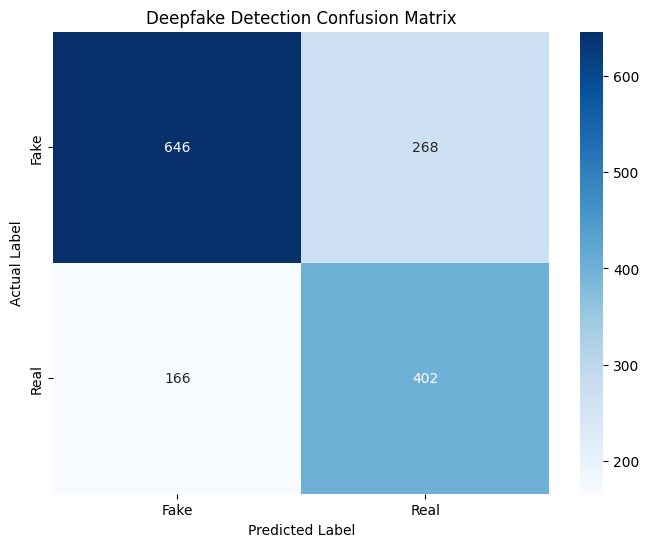


Classification Report:
              precision    recall  f1-score   support

        Fake       0.80      0.71      0.75       914
        Real       0.60      0.71      0.65       568

    accuracy                           0.71      1482
   macro avg       0.70      0.71      0.70      1482
weighted avg       0.72      0.71      0.71      1482



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

print("Running final evaluation on the Test Dataset...")

test_loss, test_accuracy = model.evaluate(test_dataset)
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")


true_labels = []
for images, labels in test_dataset:
    true_labels.extend(labels.numpy().flatten())

predictions = model.predict(test_dataset)

predicted_classes = (predictions > 0.5).astype(int).flatten()

cm = confusion_matrix(true_labels, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Fake', 'Real'], 
            yticklabels=['Fake', 'Real'])
plt.title('Deepfake Detection Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

print("\nClassification Report:")
print(classification_report(true_labels, predicted_classes, target_names=['Fake', 'Real']))

In [30]:
model.save('deepfake_xception_baseline.keras')

print("Done!")

Done!
